In [27]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv(Path("../data/processed/air_quality_features.csv"), parse_dates=["timestamp"])
season_order = ["Spring", "Winter", "Summer", "Autumn"]
season_palette = {
    "Spring": "#2ca02c",
    "Winter": "#1f77b4",
    "Summer": "#ff7f0e",
    "Autumn": "#8c564b",
}

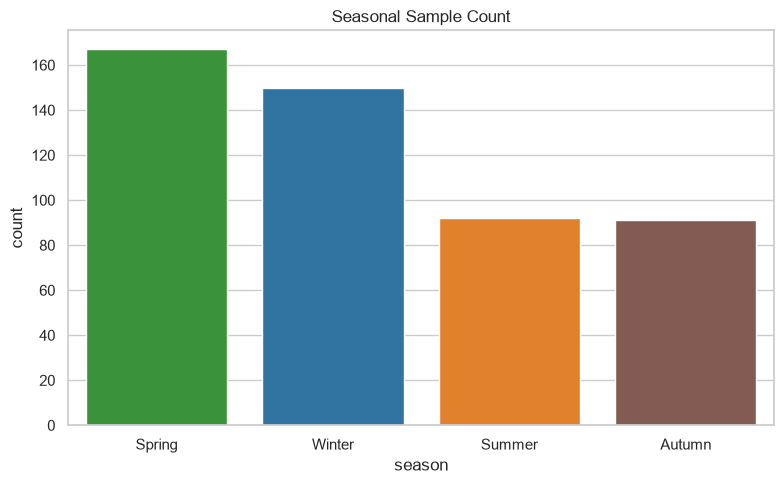

In [28]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="season", order=season_order, hue="season", palette=season_palette, legend=False)
plt.title("Seasonal Sample Count")
plt.tight_layout()
plt.show()

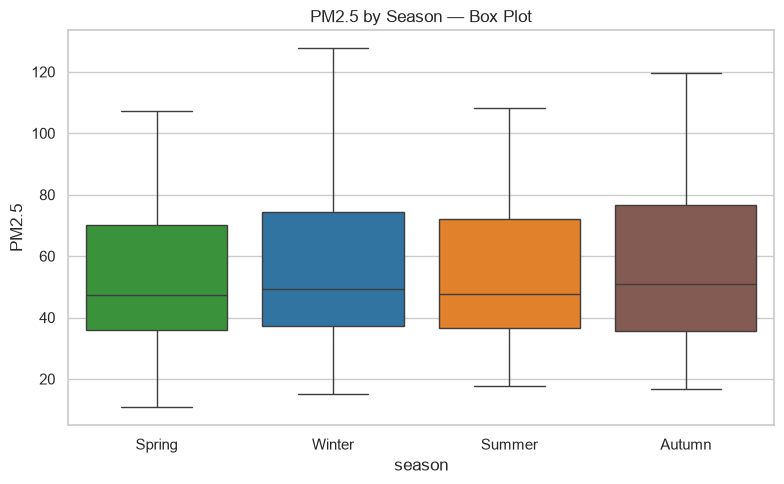

In [29]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="season", y="PM2.5", order=season_order, hue="season", palette=season_palette, legend=False)
plt.title("PM2.5 by Season — Box Plot")
plt.tight_layout()
plt.show()

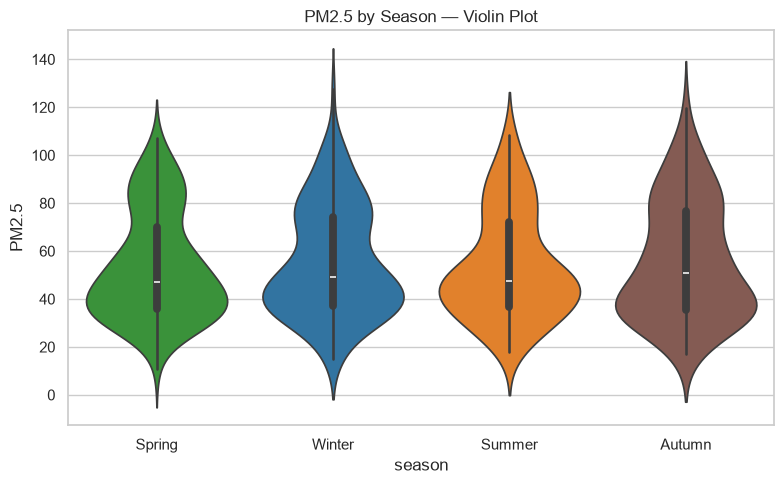

In [30]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="season", y="PM2.5", order=season_order, hue="season", palette=season_palette, legend=False)
plt.title("PM2.5 by Season — Violin Plot")
plt.tight_layout()
plt.show()

**Seasonal PM2.5 — actionable insight (from the violin plot)**

The violin plot shows the full PM2.5 distribution per season. The clearest seasonal signal is in the **upper tail**, not the center:

- **Winter carries the highest extreme values.** Its violin stretches furthest upward, with a maximum of **127.6 µg/m³** (highest of any season), a mean of **55.8**, median **49.3**, and **23.3%** of days above 75 µg/m³.
- **The other seasons look comparatively even.** Spring (mean 53.6, median 47.2), Summer (mean 53.9, median 47.5), and Autumn (mean 55.7, median 51.0) have similar centers, so the bulk of the distribution does not shift much by season.
- **Autumn deserves a caveat.** It actually has the highest mean and the widest IQR (41.3), plus **5.5%** of days above 100 µg/m³ — its own high tail. So winter is the season of the most extreme peaks, while autumn is broadly elevated and variable.

**What this means in practice**

- Seasonal averages are close (53.6–55.8 µg/m³); the real difference is the **frequency and severity of spikes**, which are worst in winter.
- Trigger **winter-focused interventions** (traffic/industrial restrictions, public health advisories, air-quality alerts) around high-PM2.5 days, with alert thresholds at 75 and 100 µg/m³.
- Keep **season** as a model feature and monitor autumn as a secondary high-risk window.
- Sample sizes are imbalanced (Spring 167, Winter 150, Summer 92, Autumn 91); treat these as descriptive patterns, not causal effects.


In [31]:
selected_months = {1: "January 2023", 6: "June 2023", 9: "September 2023"}
df_month = df[df["timestamp"].dt.year.eq(2023) & df["timestamp"].dt.month.isin(selected_months)].copy()
df_month["month_label"] = df_month["timestamp"].dt.month.map(selected_months)
df_month["day_of_month"] = df_month["timestamp"].dt.day

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
month_order = ["January 2023", "June 2023", "September 2023"]

day_means = (
    df_month.groupby(["month_label", "day_of_week"], as_index=False)["PM2.5"]
    .mean()
)
day_means

,month_label,day_of_week,PM2.5
0,January 2023,Friday,58.383175
1,January 2023,Monday,76.281275
2,January 2023,Saturday,88.367813
3,January 2023,Sunday,53.772548
4,January 2023,Thursday,60.923650
5,January 2023,Tuesday,57.206419
6,January 2023,Wednesday,48.735415
7,June 2023,Friday,66.258695
8,June 2023,Monday,59.740500
9,June 2023,Saturday,38.431497


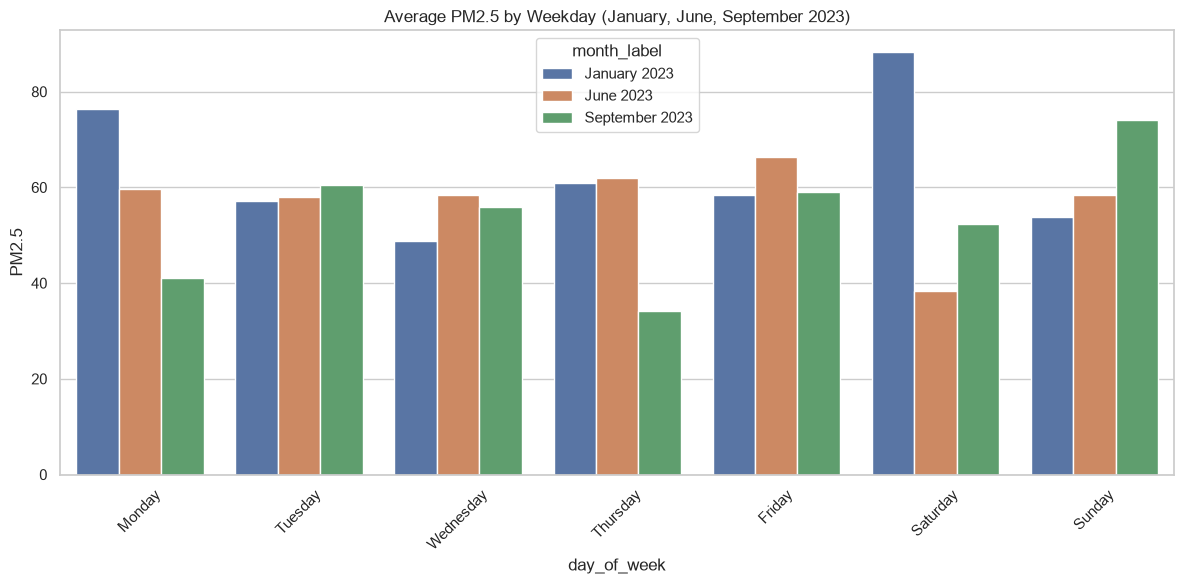

In [32]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=day_means,
    x="day_of_week",
    y="PM2.5",
    hue="month_label",
    order=weekday_order,
    hue_order=month_order,
)
plt.title("Average PM2.5 by Weekday (January, June, September 2023)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

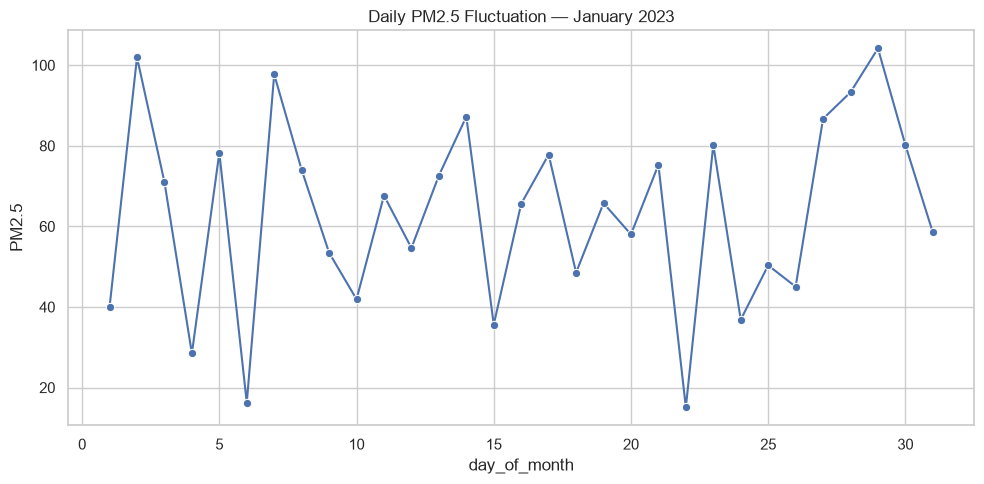

In [33]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_month[df_month["month_label"] == "January 2023"],
    x="day_of_month",
    y="PM2.5",
    marker="o",
)
plt.title("Daily PM2.5 Fluctuation — January 2023")
plt.tight_layout()
plt.show()

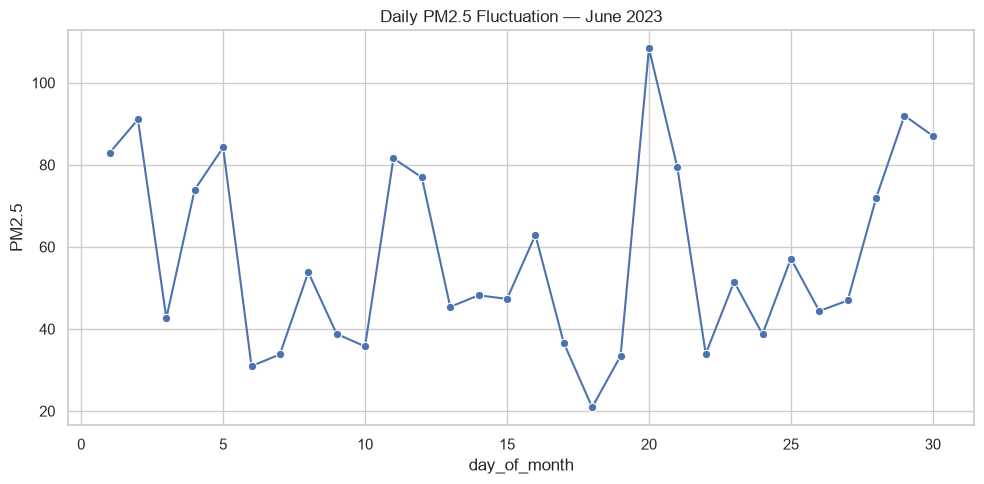

In [34]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_month[df_month["month_label"] == "June 2023"],
    x="day_of_month",
    y="PM2.5",
    marker="o",
)
plt.title("Daily PM2.5 Fluctuation — June 2023")
plt.tight_layout()
plt.show()

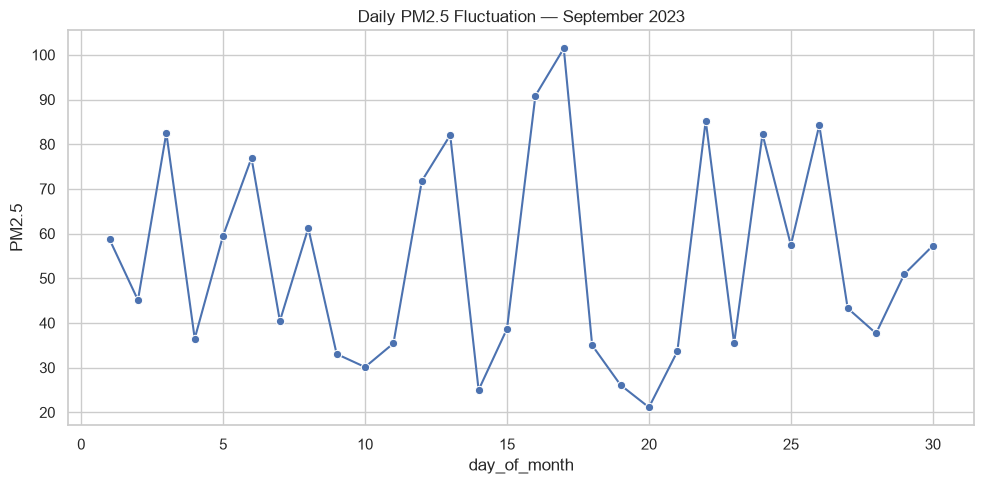

In [35]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_month[df_month["month_label"] == "September 2023"],
    x="day_of_month",
    y="PM2.5",
    marker="o",
)
plt.title("Daily PM2.5 Fluctuation — September 2023")
plt.tight_layout()
plt.show()

**Month-wise PM2.5 — actionable insight (January, June, September 2023)**

**Month-level averages**
- PM2.5 declines across the selected months: **January 63.29** → **June 57.75** → **September 53.97 µg/m³**. January is about 17% higher than September, consistent with the winter peak seen in the seasonal analysis.
- January is also the most extreme month in absolute terms: standard deviation **23.78**, range **89.08**, **11 days above 75** and **2 days above 100 µg/m³**.

**Within-month fluctuations (line charts)**
- **January:** highly spiky. It swings from **15.08** (day 22) to **104.16** (day 29); the largest one-day rise is **+81.45** (day 7) and the largest drop **-62.02** (day 6).
- **June:** range **87.47**; a sharp late-month spike reaches **108.37** on day 20 (+74.94 in one day), after a low of **20.90** on day 18.
- **September:** range **80.32**; a mid-month peak of **101.44** on day 17 (+52.16) is followed by the largest fall **-66.44** on day 18, bottoming near **21.12** on day 20.
- Relative volatility rises as the mean falls: CV is **37.6% (Jan)**, **39.8% (Jun)** and **42.5% (Sep)**. September has the lowest average but the most proportional day-to-day instability.

**Day-of-week patterns (bar chart)**
- **January:** Saturday highest (**88.37**), Monday **76.28**; Wednesday lowest (**48.74**).
- **June:** Friday highest (**66.26**), Saturday lowest (**38.43**).
- **September:** Sunday highest (**74.08**), Thursday lowest (**34.18**).
- The weekday ranking **flips between months** (e.g., Saturday is highest in January but lowest in June), so day-of-week alone is not a stable predictor — model it as a **month × weekday interaction** or with cyclical weekday features.

**What to do with this**
- Expect **short, sharp spikes** rather than smooth trends; plan for spike detection and early warning rather than relying on monthly averages.
- Use **month** and **day-of-week interaction** as model features, and keep **rolling volatility** to capture the rapid swings.
- Alert thresholds of **75 and 100 µg/m³** would have fired on 11/9/8 days in Jan/Jun/Sep respectively, supporting month-specific alert budgets.


In [ ]:
pm25_scaled = (df["PM2.5"] - df["PM2.5"].min()) / (df["PM2.5"].max() - df["PM2.5"].min())
pm10_scaled = (df["PM10"] - df["PM10"].min()) / (df["PM10"].max() - df["PM10"].min())
co_scaled = (df["CO"] - df["CO"].min()) / (df["CO"].max() - df["CO"].min())

df["risk_score"] = 0.5 * pm25_scaled + 0.3 * pm10_scaled + 0.2 * co_scaled

df[["PM2.5", "PM10", "CO", "risk_score"]].head()

In [ ]:
risk_thresholds = df["risk_score"].quantile([0.50, 0.75, 0.90])
print(risk_thresholds.round(4).to_string())

df["risk_category"] = pd.cut(
    df["risk_score"],
    bins=[-np.inf, *risk_thresholds, np.inf],
    labels=["Low", "Medium", "High", "Critical"],
    include_lowest=True,
)

df["risk_category"].value_counts().reindex(["Low", "Medium", "High", "Critical"])

In [ ]:
df.groupby("risk_category", observed=True)[["PM2.5", "PM10", "CO", "risk_score"]].agg(["mean", "min", "max"]).round(2)

**Risk Score — actionable insight (third metric)**

A composite day-level risk index built from the three main pollution drivers:

**`risk_score = 0.5 × scaled PM2.5 + 0.3 × scaled PM10 + 0.2 × scaled CO`**

- Each feature is **min-max scaled to 0–1** before weighting, so CO (raw range ~0.4–4.8) is not drowned out by PM10 (raw range ~13–172).
- PM2.5 carries the largest weight (0.5), followed by PM10 (0.3) and CO (0.2).
- The resulting score ranges from **0.1229 to 0.8508** across the 500 days.

**Quantile thresholds (data-driven)**
- 50th percentile (**median**) = **0.3337**
- 75th percentile = **0.5798**
- 90th percentile = **0.6563**

**Categories**
- **Low:** score ≤ **0.3337** — 250 days (50%)
- **Medium:** 0.3337 < score ≤ **0.5798** — 125 days (25%)
- **High:** 0.5798 < score ≤ **0.6563** — 75 days (15%)
- **Critical:** score > **0.6563** — 50 days (10%)

**Profile of each category**
- **Low:** PM2.5 **37.4**, PM10 **62.4**, CO **1.70**
- **Medium:** PM2.5 **57.4**, PM10 **93.1**, CO **2.22**
- **High:** PM2.5 **81.9**, PM10 **117.0**, CO **2.96**
- **Critical:** PM2.5 **93.5**, PM10 **126.6**, CO **3.29**

**What this means in practice**
- The quantile split guarantees a manageable triage capacity: the top **10%** of days (Critical) and next **15%** (High) get prioritized alerts.
- Use `risk_category` as the day-level alert label: Critical days justify emergency measures (traffic/industrial restrictions, public advisories); High days justify pre-emptive warnings.
- This is a **relative index**, not a regulatory AQI. Quantile thresholds are fitted to this dataset, so re-fit them on new data or switch to fixed absolute cutoffs before operational deployment.
- Keep `risk_score` and `risk_category` as features/labels in the modeling phase.
